In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("K-Means Clustering learning started")

K-Means Clustering learning started


In [3]:
# Customer data: [Spending Score, Shopping Frequency]
X = np.array([
    [1, 2], [2, 1], [2, 3], [3, 2], [3, 3],
    [7, 8], [8, 7], [8, 9], [9, 8], [9, 9],
    [1, 8], [2, 9], [2, 7], [3, 8], [3, 9]
])

print("Dataset shape:", X.shape)
print("Number of customers:", len(X))
print("\nCustomer data:")
print(X)

Dataset shape: (15, 2)
Number of customers: 15

Customer data:
[[1 2]
 [2 1]
 [2 3]
 [3 2]
 [3 3]
 [7 8]
 [8 7]
 [8 9]
 [9 8]
 [9 9]
 [1 8]
 [2 9]
 [2 7]
 [3 8]
 [3 9]]


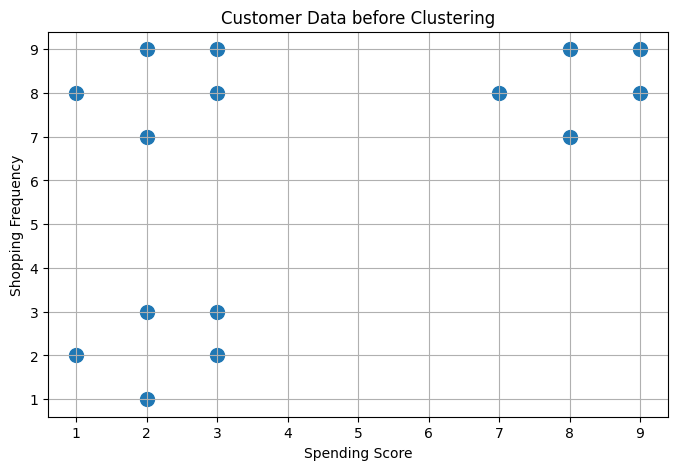

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    s=100
)

plt.xlabel("Spending Score")
plt.ylabel("Shopping Frequency")
plt.title("Customer Data before Clustering")

plt.grid(True)
plt.show()

In [6]:
# Create a K-Means model with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train the model on our customer data
kmeans.fit(X)

# Display the cluster assigned to each customer
print("Cluster labels:")
print(kmeans.labels_)

# Display the center of each cluster
print("\nCluster centroids:")
print(kmeans.cluster_centers_)


Cluster labels:
[1 1 1 1 1 2 2 2 2 2 0 0 0 0 0]

Cluster centroids:
[[2.2 8.2]
 [2.2 2.2]
 [8.2 8.2]]


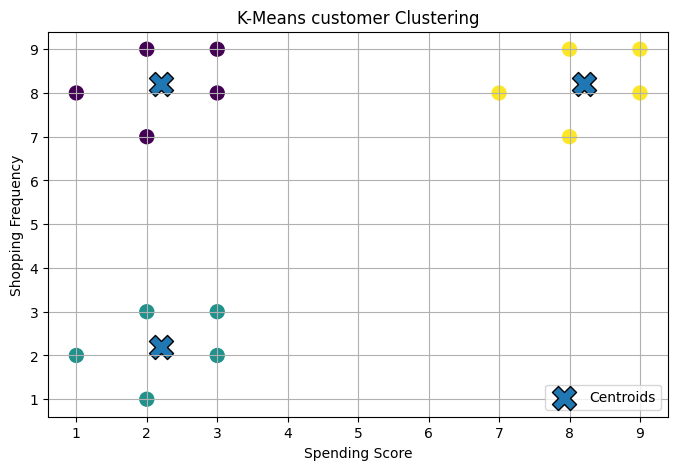

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=kmeans.labels_,
    s=100
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=300,
    edgecolors='black',
    label='Centroids'
)

plt.xlabel("Spending Score")
plt.ylabel("Shopping Frequency")
plt.title("K-Means customer Clustering")

plt.legend()
plt.grid(True)
plt.show()

In [10]:
# Calculate inertia for different values of K
for k in range(1, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)

    print("K:", k, "| Inertia:", round(model.inertia_, 2))

K: 1 | Inertia: 256.8
K: 2 | Inertia: 106.8
K: 3 | Inertia: 16.8
K: 4 | Inertia: 13.53
K: 5 | Inertia: 10.27
K: 6 | Inertia: 7.0


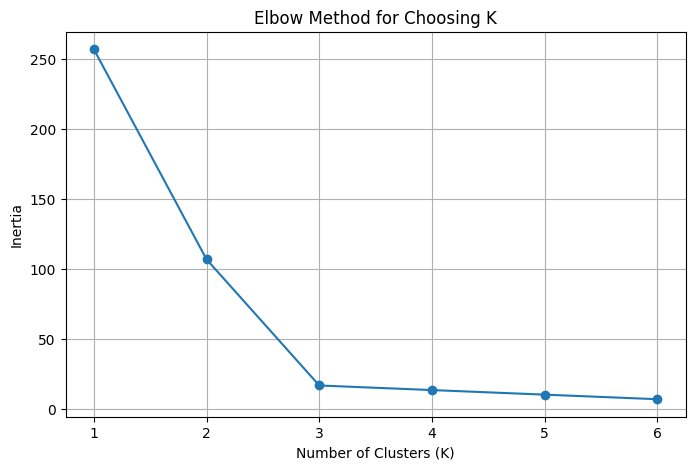

In [11]:
inertias = []

for k in range(1, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 7),
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing K")
plt.xticks(range(1, 7))
plt.grid(True)
plt.show()

In [12]:
# Compare clustering quality for different K values
for k in range(2, 6):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    print(
        "K:", k,
        "| Silhouette Score:", round(score, 3)
    )

K: 2 | Silhouette Score: 0.537
K: 3 | Silhouette Score: 0.723
K: 4 | Silhouette Score: 0.578
K: 5 | Silhouette Score: 0.451
